In [8]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")


Libraries imported successfully!


In [10]:

# Path to our original CSV file
file_path = "/content/drive/MyDrive/SriLanka_Vegetable_Price_ML/data/raw/daily-prices-d.csv"

# Read the dataset
df = pd.read_csv(file_path, comment="#")

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display first 5 rows
display(df.head())


Dataset Shape: (2472, 263)


,period,"Beans (wholesale, pettah) (Rs/kg)","Beans (wholesale, dambulla) (Rs/kg)","Beans (retail, dambulla) (Rs/kg)","Beans (retail, narahenpita) (Rs/kg)","Carrot (wholesale, pettah) (Rs/kg)","Carrot (wholesale, dambulla) (Rs/kg)","Carrot (retail, dambulla) (Rs/kg)","Carrot (retail, narahenpita) (Rs/kg)","Cabbage (wholesale, pettah) (Rs/kg)",...,"Hurulla (wholesale, narahenpita) (Rs/kg)","Dried chilli (imp) (wholesale, narahenpita) (Rs/kg)","Red onion (local) (wholesale, narahenpita) (Rs/kg)","Coconut (retail, narahenpita) (Rs/nut)","Dhal (small) (retail, narahenpita) (Rs/kg)","Sugar (retail, narahenpita) (Rs/kg)","Egg (retail, narahenpita) (Rs/each)","Dhal (small) (retail, pettah) (Rs/kg)","Apple (imp) (retail, dambulla) (Rs/each)","Orange (imp) (retail, dambulla) (Rs/each)"
0,2016-08-01,140.0,130.0,165.0,NaN,100.0,120.0,155.0,NaN,80.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-08-02,140.0,145.0,190.0,NaN,100.0,110.0,155.0,NaN,80.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-08-03,120.0,155.0,190.0,NaN,100.0,100.0,150.0,NaN,70.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-08-04,105.0,150.0,190.0,NaN,100.0,90.0,145.0,NaN,60.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-08-05,105.0,150.0,190.0,NaN,100.0,95.0,145.0,NaN,60.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:

# Display dataset information
print("DATASET INFORMATION")
df.info()

# Check missing values
print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

# Check date range
dates = pd.to_datetime(df["period"], errors="coerce")

print("\nEARLIEST DATE:", dates.min())
print("LATEST DATE:", dates.max())
print("INVALID DATES:", dates.isna().sum())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2472 entries, 0 to 2471
Columns: 263 entries, period to Orange (imp) (retail, dambulla) (Rs/each)
dtypes: float64(262), object(1)
memory usage: 5.0+ MB

TOTAL MISSING VALUES:
315115

DUPLICATE ROWS:
0

EARLIEST DATE: 2016-08-01 00:00:00
LATEST DATE: 2026-11-20 00:00:00
INVALID DATES: 0


In [12]:
import pandas as pd

In [13]:
df = pd.read_csv(file_path, comment="#")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (2472, 263)


,period,"Beans (wholesale, pettah) (Rs/kg)","Beans (wholesale, dambulla) (Rs/kg)","Beans (retail, dambulla) (Rs/kg)","Beans (retail, narahenpita) (Rs/kg)","Carrot (wholesale, pettah) (Rs/kg)","Carrot (wholesale, dambulla) (Rs/kg)","Carrot (retail, dambulla) (Rs/kg)","Carrot (retail, narahenpita) (Rs/kg)","Cabbage (wholesale, pettah) (Rs/kg)",...,"Hurulla (wholesale, narahenpita) (Rs/kg)","Dried chilli (imp) (wholesale, narahenpita) (Rs/kg)","Red onion (local) (wholesale, narahenpita) (Rs/kg)","Coconut (retail, narahenpita) (Rs/nut)","Dhal (small) (retail, narahenpita) (Rs/kg)","Sugar (retail, narahenpita) (Rs/kg)","Egg (retail, narahenpita) (Rs/each)","Dhal (small) (retail, pettah) (Rs/kg)","Apple (imp) (retail, dambulla) (Rs/each)","Orange (imp) (retail, dambulla) (Rs/each)"
0,2016-08-01,140.0,130.0,165.0,NaN,100.0,120.0,155.0,NaN,80.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-08-02,140.0,145.0,190.0,NaN,100.0,110.0,155.0,NaN,80.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-08-03,120.0,155.0,190.0,NaN,100.0,100.0,150.0,NaN,70.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-08-04,105.0,150.0,190.0,NaN,100.0,90.0,145.0,NaN,60.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-08-05,105.0,150.0,190.0,NaN,100.0,95.0,145.0,NaN,60.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:

# STEP 2.1: Missing Value Analysis

# Total number of missing values
total_missing = df.isnull().sum().sum()

# Total number of cells
total_cells = df.size

# Calculate missing percentage
missing_percentage = (total_missing / total_cells) * 100

print("===== MISSING VALUE ANALYSIS =====")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Cells:", total_cells)
print("Total Missing Values:", total_missing)
print(f"Missing Percentage: {missing_percentage:.2f}%")

# Missing values in each column
missing_per_column = df.isnull().sum()

# Display the 15 columns with the most missing values
print("\nTOP 15 COLUMNS WITH MISSING VALUES:")
display(
    missing_per_column.sort_values(ascending=False).head(15)
)


===== MISSING VALUE ANALYSIS =====
Total Rows: 2472
Total Columns: 263
Total Cells: 650136
Total Missing Values: 315115
Missing Percentage: 48.47%

TOP 15 COLUMNS WITH MISSING VALUES:


,0
"Coconut oil (wholesale, pettah, rs/kg) (Rs/kg)",2470
"Coconut oil (retail, pettah, rs/kg) (Rs/kg)",2470
"Hurulla (wholesale, narahenpita) (Rs/kg)",2470
"Thalapath (wholesale, narahenpita) (Rs/kg)",2468
"Red onion (imp) (wholesale, narahenpita) (Rs/kg)",2468
"Balaya (wholesale, narahenpita) (Rs/kg)",2466
"Dhal (whole) (wholesale, pettah) (Rs/kg)",2466
"Red onion (local) (wholesale, narahenpita) (Rs/kg)",2465
"Orange (imp) (retail, dambulla) (Rs/each)",2464
"Paraw (wholesale, narahenpita) (Rs/kg)",2464


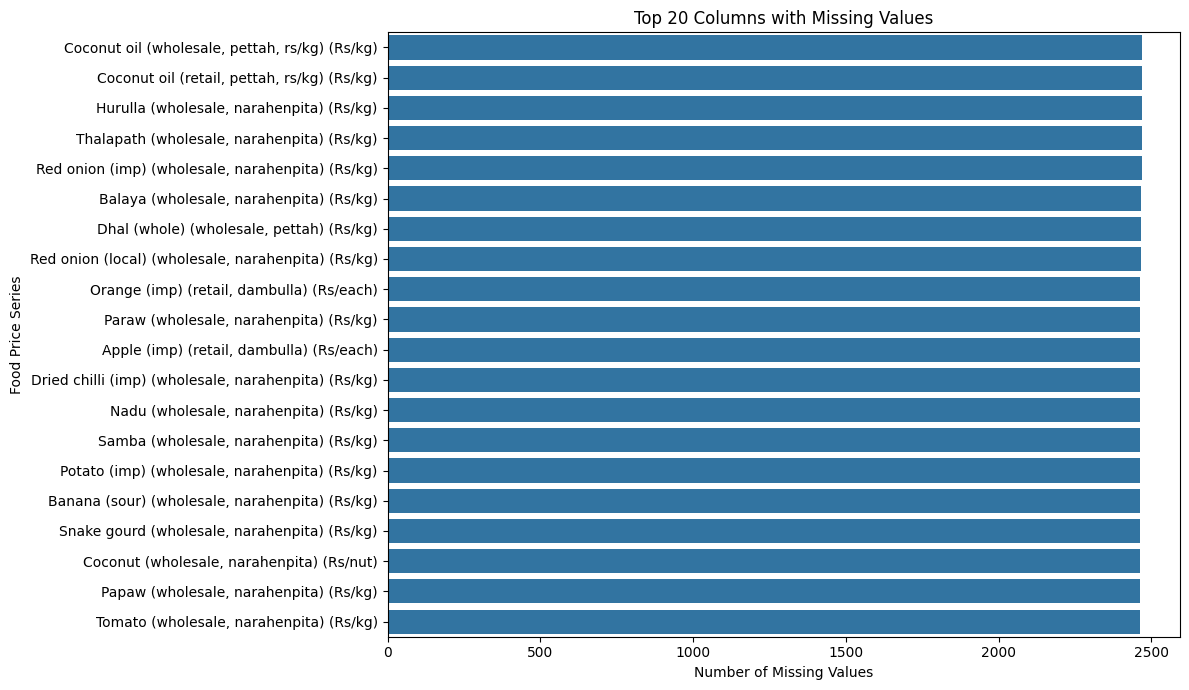

In [15]:

# STEP 2.2: Missing Values Visualization

# Select 20 columns with the most missing values
top_missing = (
    df.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_missing.values,
    y=top_missing.index
)

plt.title("Top 20 Columns with Missing Values")
plt.xlabel("Number of Missing Values")
plt.ylabel("Food Price Series")

plt.tight_layout()
plt.show()


In [16]:

# STEP 3.1: Select Vegetable Columns

vegetables = [
    "Beans",
    "Carrot",
    "Cabbage",
    "Tomato",
    "Brinjal",
    "Pumpkin",
    "Snake gourd",
    "Green chilli"
]

# Select columns belonging to our vegetables
vegetable_columns = [
    col for col in df.columns
    if any(
        col.lower().startswith(veg.lower() + " (")
        for veg in vegetables
    )
]

print("Number of vegetable price columns:",
      len(vegetable_columns))

print("\nSelected vegetable columns:")
for col in vegetable_columns:
    print(col)


Number of vegetable price columns: 48

Selected vegetable columns:
Beans (wholesale, pettah) (Rs/kg)
Beans (wholesale, dambulla) (Rs/kg)
Beans (retail, dambulla) (Rs/kg)
Beans (retail, narahenpita) (Rs/kg)
Carrot (wholesale, pettah) (Rs/kg)
Carrot (wholesale, dambulla) (Rs/kg)
Carrot (retail, dambulla) (Rs/kg)
Carrot (retail, narahenpita) (Rs/kg)
Cabbage (wholesale, pettah) (Rs/kg)
Cabbage (wholesale, dambulla) (Rs/kg)
Cabbage (retail, dambulla) (Rs/kg)
Cabbage (retail, narahenpita) (Rs/kg)
Tomato (wholesale, pettah) (Rs/kg)
Tomato (wholesale, dambulla) (Rs/kg)
Tomato (retail, dambulla) (Rs/kg)
Tomato (retail, narahenpita) (Rs/kg)
Brinjal (wholesale, pettah) (Rs/kg)
Brinjal (wholesale, dambulla) (Rs/kg)
Brinjal (retail, dambulla) (Rs/kg)
Brinjal (retail, narahenpita) (Rs/kg)
Pumpkin (wholesale, pettah) (Rs/kg)
Pumpkin (wholesale, dambulla) (Rs/kg)
Pumpkin (retail, dambulla) (Rs/kg)
Pumpkin (retail, narahenpita) (Rs/kg)
Snake gourd (wholesale, pettah) (Rs/kg)
Snake gourd (wholesale, dam

In [17]:

# STEP 3.2: Vegetable Missing Value Analysis

vegetable_df = df[["period"] + vegetable_columns].copy()

coverage = pd.DataFrame({
    "Column": vegetable_columns,
    "Available": vegetable_df[vegetable_columns].notna().sum().values,
    "Missing": vegetable_df[vegetable_columns].isna().sum().values
})

coverage["Coverage (%)"] = (
    coverage["Available"] / len(vegetable_df) * 100
).round(2)

coverage = coverage.sort_values(
    by="Coverage (%)",
    ascending=False
)

print("===== VEGETABLE DATA COVERAGE =====")

print("Total vegetable columns:", len(vegetable_columns))

print(
    "Total available vegetable price observations:",
    vegetable_df[vegetable_columns].notna().sum().sum()
)

display(coverage)


===== VEGETABLE DATA COVERAGE =====
Total vegetable columns: 48
Total available vegetable price observations: 85559


,Column,Available,Missing,Coverage (%)
17,"Brinjal (wholesale, dambulla) (Rs/kg)",2414,58,97.65
13,"Tomato (wholesale, dambulla) (Rs/kg)",2413,59,97.61
9,"Cabbage (wholesale, dambulla) (Rs/kg)",2412,60,97.57
1,"Beans (wholesale, dambulla) (Rs/kg)",2410,62,97.49
21,"Pumpkin (wholesale, dambulla) (Rs/kg)",2408,64,97.41
5,"Carrot (wholesale, dambulla) (Rs/kg)",2400,72,97.09
25,"Snake gourd (wholesale, dambulla) (Rs/kg)",2398,74,97.01
0,"Beans (wholesale, pettah) (Rs/kg)",2393,79,96.80
20,"Pumpkin (wholesale, pettah) (Rs/kg)",2393,79,96.80
12,"Tomato (wholesale, pettah) (Rs/kg)",2393,79,96.80


In [18]:

# Select vegetable series with >= 60% coverage

coverage_threshold = 60

usable_columns = coverage.loc[
    coverage["Coverage (%)"] >= coverage_threshold,
    "Column"
].tolist()

excluded_columns = coverage.loc[
    coverage["Coverage (%)"] < coverage_threshold,
    "Column"
].tolist()

# Create a separate DataFrame
usable_df = df[["period"] + usable_columns].copy()

print("===== COLUMN SELECTION RESULTS =====")
print("Original vegetable series:", len(vegetable_columns))
print("Retained series:", len(usable_columns))
print("Excluded series:", len(excluded_columns))

print("\nAvailable observations in retained series:")
print(usable_df[usable_columns].notna().sum().sum())

print("\nExcluded series:")
for col in excluded_columns:
    print("-", col)


===== COLUMN SELECTION RESULTS =====
Original vegetable series: 48
Retained series: 40
Excluded series: 8

Available observations in retained series:
85471

Excluded series:
- Beans (wholesale, narahenpita) (Rs/kg)
- Carrot (wholesale, narahenpita) (Rs/kg)
- Cabbage (wholesale, narahenpita) (Rs/kg)
- Tomato (wholesale, narahenpita) (Rs/kg)
- Brinjal (wholesale, narahenpita) (Rs/kg)
- Pumpkin (wholesale, narahenpita) (Rs/kg)
- Snake gourd (wholesale, narahenpita) (Rs/kg)
- Green chilli (wholesale, narahenpita) (Rs/kg)


In [19]:

#  Check date ranges and reporting gaps

audit_df = usable_df.copy()

audit_df["period"] = pd.to_datetime(
    audit_df["period"], errors="coerce"
)

audit_df = audit_df.sort_values("period")

gap_results = []

for col in usable_columns:

    observed = audit_df.loc[
        audit_df[col].notna(), "period"
    ].dropna().sort_values()

    if len(observed) < 2:
        continue

    # Gaps between consecutive actual observations
    gaps = observed.diff().dt.days.dropna()

    gap_results.append({
        "Series": col,
        "First Date": observed.min().date(),
        "Last Date": observed.max().date(),
        "Observations": len(observed),
        "Maximum Gap (days)": gaps.max(),
        "Median Gap (days)": gaps.median(),
        "Gaps Over 7 Days": (gaps > 7).sum()
    })

gap_report = pd.DataFrame(gap_results)

display(
    gap_report.sort_values(
        "Maximum Gap (days)",
        ascending=False
    )
)


,Series,First Date,Last Date,Observations,Maximum Gap (days),Median Gap (days),Gaps Over 7 Days
24,"Snake gourd (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2324,118.0,1.0,6
25,"Cabbage (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2323,118.0,1.0,6
26,"Brinjal (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2323,118.0,1.0,6
27,"Pumpkin (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2318,118.0,1.0,7
31,"Green chilli (retail, pettah) (Rs/kg)",2019-06-03,2026-11-20,1652,118.0,1.0,5
22,"Carrot (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2324,118.0,1.0,6
21,"Tomato (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2324,118.0,1.0,6
23,"Beans (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2324,118.0,1.0,6
13,"Snake gourd (wholesale, pettah) (Rs/kg)",2016-08-01,2026-11-20,2391,56.0,1.0,5
9,"Tomato (wholesale, pettah) (Rs/kg)",2016-08-01,2026-11-20,2393,56.0,1.0,5


In [20]:

# STEP 4.3: Save audit reports

report_folder = (
    "/content/drive/MyDrive/"
    "SriLanka_Vegetable_Price_ML/reports"
)

os.makedirs(report_folder, exist_ok=True)

coverage.to_csv(
    f"{report_folder}/vegetable_coverage_report.csv",
    index=False
)

gap_report.to_csv(
    f"{report_folder}/vegetable_gap_report.csv",
    index=False
)

print("Audit reports saved successfully!")


Audit reports saved successfully!


In [21]:

#  Summarize my reporting gaps

print("REPORTING GAP SUMMARY")

print("Total retained series:", len(gap_report))

print("\nMaximum gap across all series:")
print(gap_report["Maximum Gap (days)"].max())

print("\nSeries with gaps longer than 30 days:")
print(
    (gap_report["Maximum Gap (days)"] > 30).sum()
)

print("\nTop 10 longest gaps:")
display(
    gap_report.sort_values(
        "Maximum Gap (days)",
        ascending=False
    ).head(10)
)


REPORTING GAP SUMMARY
Total retained series: 40

Maximum gap across all series:
118.0

Series with gaps longer than 30 days:
24

Top 10 longest gaps:


,Series,First Date,Last Date,Observations,Maximum Gap (days),Median Gap (days),Gaps Over 7 Days
24,"Snake gourd (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2324,118.0,1.0,6
25,"Cabbage (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2323,118.0,1.0,6
26,"Brinjal (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2323,118.0,1.0,6
27,"Pumpkin (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2318,118.0,1.0,7
31,"Green chilli (retail, pettah) (Rs/kg)",2019-06-03,2026-11-20,1652,118.0,1.0,5
22,"Carrot (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2324,118.0,1.0,6
21,"Tomato (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2324,118.0,1.0,6
23,"Beans (retail, pettah) (Rs/kg)",2016-08-01,2026-11-20,2324,118.0,1.0,6
13,"Snake gourd (wholesale, pettah) (Rs/kg)",2016-08-01,2026-11-20,2391,56.0,1.0,5
9,"Tomato (wholesale, pettah) (Rs/kg)",2016-08-01,2026-11-20,2393,56.0,1.0,5
